# Two solids in thermal contact
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/meyer-nils/torch-fem/blob/main/examples/basic/assembly/conductance.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/meyer-nils/torch-fem/main?labpath=examples/basic/assembly/conductance.ipynb)

Two bars of different conductivity meet at an interface with a finite contact
conductance. One end is held at a fixed temperature, the other cools by convection
to ambient. An `Assembly` exchanges heat across the interface with
`conductance(...)`, and the steady temperature profile is compared with the series
of thermal resistances.

In [1]:
import matplotlib.pyplot as plt
import torch

from torchfem import Assembly, SolidHeat
from torchfem.materials import IsotropicConductivity3D
from torchfem.mesh import cube_hexa

torch.set_default_dtype(torch.float64)

# Bars of length L with a square cross section of edge W
L = 1.0
W = 0.2

# Conductivities of the bars, contact conductance at the interface, and film
# coefficient and ambient temperature at the cooled end
kappa_a = 50.0
kappa_b = 200.0
h_contact = 500.0
h_film = 25.0
T_hot = 100.0
T_ambient = 20.0

## Two bars

In [2]:
# Both bars carry the same cross-section mesh, so their interface nodes coincide
nodes_a, elements_a = cube_hexa(11, 3, 3, L, W, W)
nodes_b, elements_b = cube_hexa(11, 3, 3, L, W, W)
nodes_b += torch.tensor([L, 0.0, 0.0])

bar_a = SolidHeat(nodes_a, elements_a, IsotropicConductivity3D(kappa_a))
bar_b = SolidHeat(nodes_b, elements_b, IsotropicConductivity3D(kappa_b))

# Fixed temperature at the hot end
hot = nodes_a[:, 0] == 0.0
bar_a.constraints[hot] = True
bar_a.temperatures[hot, 0] = T_hot

# Convection to ambient at the cooled end
bar_b.convection(nodes_b[:, 0] == 2 * L, h_film, T_ambient)

## Assembly

In [3]:
assembly = Assembly([bar_a, bar_b])
interface_b = nodes_b[:, 0] == L
interface_a = nodes_a[:, 0] == L
assembly.conductance(bar_b, interface_b, bar_a, h_contact, interface_a)

T, _, _, _, _ = assembly.solve()

assembly.plot(node_property={"Temperature": T}, colormap="magma")

EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

## Comparison with the analytical solution

The heat flux $q$ through the bars follows from the thermal resistances in series:
the conduction through each bar, the contact at the interface and the film at the
cooled end. The temperature falls linearly in each bar, jumps by $q / h_\text{contact}$
at the interface and ends $q / h_\text{film}$ above ambient.

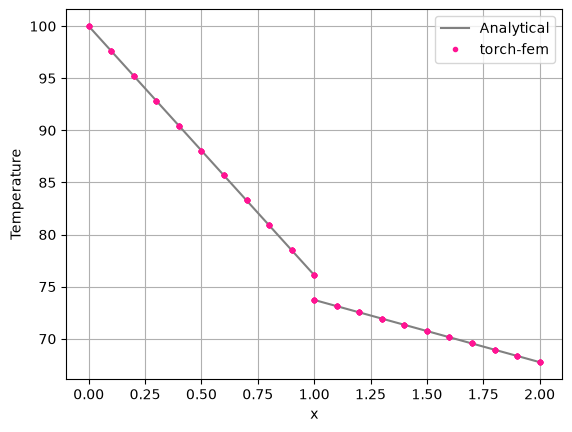

In [4]:
# Heat flux through the series of thermal resistances
q = (T_hot - T_ambient) / (L / kappa_a + 1 / h_contact + L / kappa_b + 1 / h_film)

# Linear in each bar, with a jump at the interface
x_a = torch.tensor([0.0, L])
x_b = torch.tensor([L, 2 * L])
T_a = T_hot - q * x_a / kappa_a
T_b = T_a[-1] - q / h_contact - q * (x_b - L) / kappa_b

plt.plot(x_a, T_a, "-", color="gray", label="Analytical")
plt.plot(x_b, T_b, "-", color="gray")
plt.plot(nodes_a[:, 0], T[0].ravel(), ".", color="deeppink", label="torch-fem")
plt.plot(nodes_b[:, 0], T[1].ravel(), ".", color="deeppink")
plt.xlabel("x")
plt.ylabel("Temperature")
plt.grid()
plt.legend()
plt.show()